# Lab 02 — Real Hubble Diagram: Residuals, Bootstrap and Statistical Evidence

https://drive.google.com/drive/folders/16AmPEDZvtsGXka1OHXOYjEZY8QvClSFB
https://docs.google.com/presentation/d/1qAkstI9PonTVowzeh7MnW1-nzWqtHtR_/edit?slide=id.p1#slide=id.p1
https://docs.google.com/presentation/d/1E3xEh4PTg8JG0W6TSh_L2OcWW4UCYS6h/edit?slide=id.p39#slide=id.p39


**Course:** MSc Astrostatistics for Observational Cosmology  
**Format:** 4-hour hands-on practical + graded extension  
**Status:** **Graded Lab 1 (5%)**  
**Real data:** Pantheon+ / SH0ES

> ## Scientific question
> **What statistical structure is visible in the real Hubble diagram before a full cosmological fit?**

This lab develops the statistical habits needed for the rest of the course:

$$\text{estimate} + \text{uncertainty} + \text{diagnostic} + \text{interpretation}.
$$

We use the published `MU_SH0ES` only as a real, calibrated distance-modulus product for exploratory Hubble-diagram statistics. It is **not** an independent measurement of \(H_0\), because its absolute scale already incorporates SH0ES calibration information.

The diagonal uncertainty column is used for visualization only. We do **not** fit cosmological parameters with it.

# 0. Learning outcomes

By the end you should be able to:

- construct a reference Hubble residual;
- explain the difference between a reference model and an inferred model;
- bootstrap at the correct physical unit;
- report an effect size with an interval rather than only a \(p\)-value;
- perform a permutation test without assuming a Gaussian sampling distribution;
- use robust summaries and empirical CDFs;
- distinguish descriptive structure from cosmological inference.

## 1. Five-line statistical statement

Complete before looking at the residual results.

**Estimand:** difference between the median Hubble residuals of low and high redshift of supernovae. 

**Observed data:** We have the redshift, the distance modulus, and the uncertainties. 

**Generative assumptions:** We assume that we can compare distances with a cosmological model, considering uncertainties. 

**Uncertainty / selection:** Calibration differences, erros while doing measurements. 

**Validation / falsification test:** We use bootstrap and permutation to evaluate the uncertainty and the differences between redshifts. 

In [1]:
from pathlib import Path
import io, sys, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from astropy.cosmology import FlatLambdaCDM

SEED = 2026
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 60)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.14.6
NumPy: 2.4.6
Pandas: 3.0.3


## 2. Load the same real Pantheon+ table

In [2]:
PANTHEON_URL = (
    "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/"
    "Pantheon%2B_Data/4_DISTANCES_AND_COVAR/Pantheon%2BSH0ES.dat"
)

def load_pantheon(url=PANTHEON_URL):
    """Download the published Pantheon+SH0ES high-level table."""
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), sep=r"\s+")

sn = load_pantheon()
print(f"Rows: {len(sn):,}")
print(f"Unique CID values: {sn['CID'].nunique():,}")
display(sn.head())

Rows: 1,701
Unique CID values: 1,543


,CID,IDSURVEY,zHD,zHDERR,zCMB,zCMBERR,zHEL,zHELERR,m_b_corr,m_b_corr_err_DIAG,MU_SH0ES,MU_SH0ES_ERR_DIAG,CEPH_DIST,IS_CALIBRATOR,USED_IN_SH0ES_HF,c,cERR,x1,x1ERR,mB,mBERR,x0,x0ERR,COV_x1_c,COV_x1_x0,COV_c_x0,RA,DEC,HOST_RA,HOST_DEC,HOST_ANGSEP,VPEC,VPECERR,MWEBV,HOST_LOGMASS,HOST_LOGMASS_ERR,PKMJD,PKMJDERR,NDOF,FITCHI2,FITPROB,m_b_corr_err_RAW,m_b_corr_err_VPEC,biasCor_m_b,biasCorErr_m_b,biasCor_m_b_COVSCALE,biasCor_m_b_COVADD
0,2011fe,51,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.74571,1.516210,28.9987,1.516450,29.1770,1,0,-0.107600,0.040080,-0.548188,0.133730,9.58436,0.032722,2.63181,0.079318,0.000114,-0.000525,-0.002728,210.774,54.2737,-999,-999,-9.0,0.0,250,0.007589,10.67700,-9.000,55815.0,0.1071,36,26.8859,0.864470,0.0991,1.4960,0.0381,0.005,1.0,0.003
1,2011fe,56,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.80286,1.517230,29.0559,1.517470,29.1770,1,0,-0.032895,0.038463,-0.380481,0.086100,9.78448,0.035244,2.18880,0.071051,-0.000444,-0.001502,-0.002201,210.774,54.2737,-999,-999,-9.0,0.0,250,0.007589,10.67700,0.000,55815.2,0.0579,101,88.3064,0.812220,0.0971,1.4960,-0.0252,0.003,1.0,0.004
2,2012cg,51,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.47030,0.781906,30.7233,0.782372,30.8433,1,0,0.100730,0.018231,0.491960,0.023545,11.81610,0.023712,0.33695,0.007359,-0.000061,0.000009,-0.000111,186.803,9.4203,-999,-999,-9.0,0.0,250,0.017772,9.63300,0.002,56082.4,0.0278,165,233.5000,0.000358,0.0399,0.7134,0.0545,0.019,1.0,0.036
3,2012cg,56,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.49190,0.798612,30.7449,0.799068,30.8433,1,0,0.122470,0.039030,0.712610,0.083554,11.88010,0.035961,0.31765,0.010521,0.000223,-0.000137,-0.000344,186.803,9.4203,-999,-999,-9.0,0.0,250,0.017772,9.63300,0.004,56082.4,0.0667,55,100.1220,0.000193,0.0931,0.7134,0.0622,0.028,1.0,0.040
4,1994DRichmond,50,0.00299,0.00084,0.00299,0.00004,0.00187,0.00004,11.52270,0.880798,30.7757,0.881212,-9.0000,0,0,-0.111684,0.026044,-1.618030,0.049543,11.53340,0.032255,0.43715,0.012987,-0.000099,-0.000035,-0.000291,188.510,7.7016,-999,-999,-9.0,0.0,250,0.019104,8.46247,-9.000,49432.6,0.0522,146,109.8390,0.988740,0.0567,0.6110,0.0650,0.009,1.0,0.006


## 3. Build an object-level exploratory table

Pantheon+ can contain multiple light-curve entries for one physical SN. For this **descriptive resampling lab**, we collapse repeated `CID` rows so that our bootstrap unit is the physical SN.

This object-level table is an instructional construct for descriptive statistics only; it is **not** a replacement for the released covariance-aware cosmology likelihood.

We use medians across repeated rows to avoid treating one SN observed by multiple surveys as several independent bootstrap objects.

In [3]:
cols = ["CID","zHD","MU_SH0ES","MU_SH0ES_ERR_DIAG","IS_CALIBRATOR"]

obj = (
    sn[cols]
    .replace([np.inf,-np.inf], np.nan)
    .dropna(subset=["CID","zHD","MU_SH0ES"])
    .groupby("CID", as_index=False)
    .agg(
        zHD=("zHD","median"),
        MU_SH0ES=("MU_SH0ES","median"),
        MU_ERR_DIAG=("MU_SH0ES_ERR_DIAG","median"),
        IS_CALIBRATOR=("IS_CALIBRATOR","max")
    )
)

# We exclude very local objects for this descriptive Hubble-flow exercise.
analysis = obj[(obj["zHD"] > 0.01) & (obj["IS_CALIBRATOR"] == 0)].copy()

print("Unique physical SNe in object-level table:", len(obj))
print("Analysis objects after descriptive cuts:", len(analysis))
display(analysis.head())

Unique physical SNe in object-level table: 1543
Analysis objects after descriptive cuts: 1466


,CID,zHD,MU_SH0ES,MU_ERR_DIAG,IS_CALIBRATOR
0,000006,0.23041,40.3062,0.260109,0
1,000010,0.24585,40.4318,0.167359,0
2,000011,0.38153,41.6775,0.218983,0
3,000014,0.13614,38.9771,0.206627,0
4,000034,0.25330,40.3688,0.157050,0


### Question

**1. Why do we exclude Cepheid calibrators from this particular Hubble-flow residual exercise?**

**2.Why does this **not** mean calibrators are unimportant for the distance ladder?**

Cepheids are variable stars that pulses, with their periods qe can determine their distances. So we exclude them so we can focus ob supernova in the Hubble flow, rather than objects that we use for calibration. 

However, Cepheid calibration still help us determine the true brightness of supernova. So it helps calibrate the Suopernova Ia disntances in the distance ladder. 

# Part I — Reference Hubble diagram

## 4. Define a reference cosmology

We choose a reference flat-$\Lambda\$CDM curve:

$$
H_0^{\rm ref}=73~{\rm km\,s^{-1}\,Mpc^{-1}},
\qquad
\Omega_m^{\rm ref}=0.30.
$$

These values are **not estimated in this lab**.

They define a baseline against which residual structure is displayed.

In [4]:
H0_REF = 73.0
OM0_REF = 0.30

cosmo_ref = FlatLambdaCDM(H0=H0_REF, Om0=OM0_REF, Tcmb0=2.725)

analysis["MU_REF"] = cosmo_ref.distmod(analysis["zHD"].to_numpy()).value
analysis["RESID"] = analysis["MU_SH0ES"] - analysis["MU_REF"]

display(analysis[["CID","zHD","MU_SH0ES","MU_REF","RESID"]].head())

,CID,zHD,MU_SH0ES,MU_REF,RESID
0,000006,0.23041,40.3062,40.210256,0.095944
1,000010,0.24585,40.4318,40.369701,0.062099
2,000011,0.38153,41.6775,41.472322,0.205178
3,000014,0.13614,38.9771,38.945296,0.031804
4,000034,0.25330,40.3688,40.443366,-0.074566


## 5. Plot the Hubble diagram and residuals

A useful Hubble-diagram figure should separate the large monotonic distance–redshift trend from the much smaller residual structure.

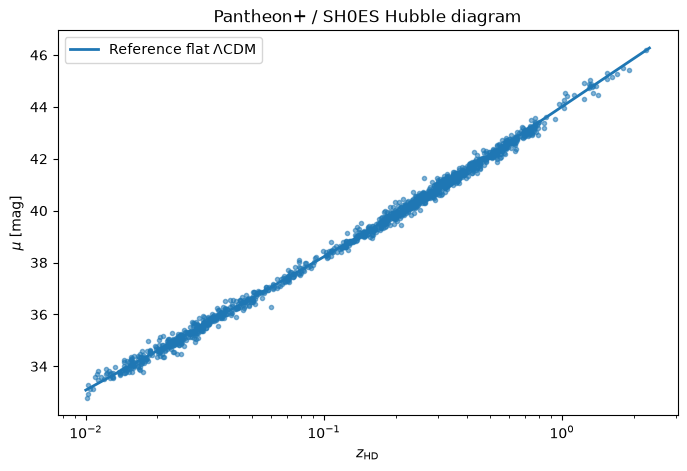

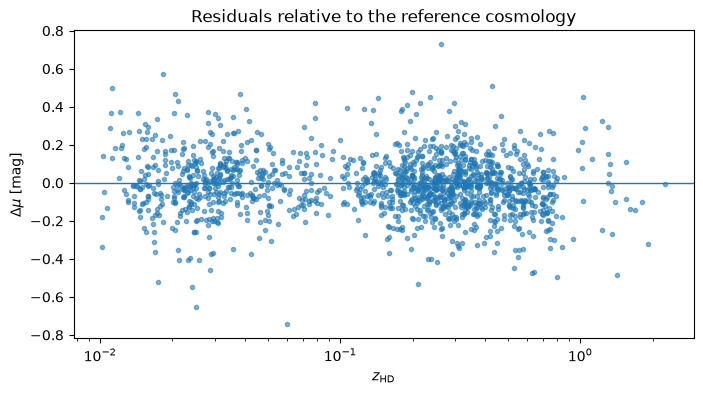

In [5]:
zgrid = np.geomspace(0.01, max(analysis["zHD"])*1.03, 500)
mugrid = cosmo_ref.distmod(zgrid).value

fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(analysis["zHD"], analysis["MU_SH0ES"], s=9, alpha=0.55)
ax.plot(zgrid, mugrid, lw=2, label="Reference flat ΛCDM")
ax.set_xscale("log")
ax.set_xlabel(r"$z_{\rm HD}$")
ax.set_ylabel(r"$\mu$ [mag]")
ax.set_title("Pantheon+ / SH0ES Hubble diagram")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
ax.axhline(0, lw=1)
ax.scatter(analysis["zHD"], analysis["RESID"], s=9, alpha=0.55)
ax.set_xscale("log")
ax.set_xlabel(r"$z_{\rm HD}$")
ax.set_ylabel(r"$\Delta\mu$ [mag]")
ax.set_title("Residuals relative to the reference cosmology")
plt.show()

### Exercise 1

Calculate:

- mean residual;
- median residual;
- standard deviation;
- MAD;
- 16th, 50th and 84th percentiles.

Then answer:

> If the mean and median differ, what does that tell you—and what does it **not** tell you?

In [7]:
from scipy import stats
r = analysis["RESID"].to_numpy()

# TODO: fill these values.
summary = {
    "mean": np.mean(r),
    "median": np.median(r),
    "std": np.std(r, ddof=1),
    "MAD": stats.median_abs_deviation(r),
    "p16": np.percentile(r, 16),
    "p50": np.percentile(r, 50),
    "p84": np.percentile(r, 84)
}
summary

{'mean': np.float64(-0.010386267480244614),
 'median': np.float64(-0.015858015468186437),
 'std': np.float64(0.15378361466848503),
 'MAD': np.float64(0.0870559001239748),
 'p16': np.float64(-0.1412079220880244),
 'p50': np.float64(-0.015858015468186437),
 'p84': np.float64(0.12486153291059307)}

In [11]:
print("Mean:", summary["mean"])
print("Median:", summary["median"])
print("Standard deviation:", summary["std"])
print("MAD:", summary["MAD"])
print("P16:", summary["p16"])
print("P50:", summary["p50"])
print("P84:", summary["p84"])

Mean: -0.010386267480244614
Median: -0.015858015468186437
Standard deviation: 0.15378361466848503
MAD: 0.0870559001239748
P16: -0.1412079220880244
P50: -0.015858015468186437
P84: 0.12486153291059307


# Part II — Bootstrap uncertainty

## 6. Why bootstrap physical objects?

The target statistic is the median residual of the population represented by this sample.

We resample **rows of `analysis`**, because each row now corresponds to one physical `CID`.

For bootstrap sample \(b\):


$\tilde r^{(b)}
=
{\rm median}
\left(
r_{i_1},r_{i_2},\ldots,r_{i_N}
\right)$

Repeat many times to approximate the sampling distribution of the median.

**NOTES:** We have our observations, and from there we are choosieng randomply and then calculating the statistics. from there we estimate the error. We need a large number os sampling because of this. 

So bootstrap is used to estimate the uncertainty of a statistic. We randomly select values from the dataset with replacement, meaning the same observation can be selected multiple times. So we have to calculate the median residual and repeat this process many times. What we get is a distribution of medians that helps us calculate the uncertainty of our median residual. We are resampling physical objects to avoid treating multiple measurements of the same object as independent observations.

In [15]:
def bootstrap_statistic(x, statistic=np.median, n_boot=5000, rng=None):
    """Bootstrap a 1-D statistic by resampling observations with replacement."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    rng = np.random.default_rng() if rng is None else rng
    out = np.empty(n_boot)
    n = len(x)
    for b in range(n_boot):
        sample = rng.choice(x, size=n, replace=True)
        out[b] = statistic(sample)
    return out

boot_global = bootstrap_statistic(analysis["RESID"])

### Exercise 2

Using at least 5,000 bootstrap samples:

1. estimate the median residual;
2. report the 2.5th and 97.5th percentiles of the bootstrap distribution;
3. plot the bootstrap distribution;
4. mark the observed median.

**Do not** call this interval a cosmological-parameter confidence interval. It is an interval for a descriptive residual statistic under this resampling procedure.

The confidence interval tells us about the uncertainty of the median residual, not the cosmological parameters.

Observed median: -0.015858015468186437
95% confidence interval: [-0.02251404 -0.00759549]


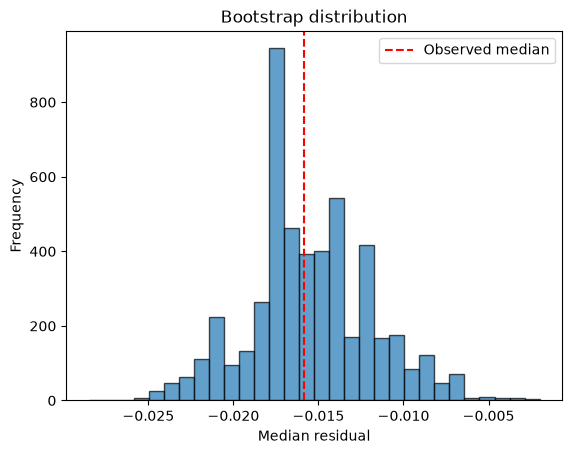

In [17]:
# TODO: after computing boot_global
# ci95 = np.percentile(boot_global, [2.5,97.5])
# ...

# Observed median residual
median_obs = np.median(r)

# bootstrap confidence interval
bootstrap = np.percentile(boot_global, [2.5, 97.5])

print("Observed median:", median_obs)
print("95% confidence interval:", bootstrap)

# Plot bootstrap distribution
plt.hist(boot_global, bins=30, edgecolor="black", alpha=0.7)

# Mark observed median
plt.axvline(median_obs, color="red", linestyle="--", label="Observed median")

plt.xlabel("Median residual")
plt.ylabel("Frequency")
plt.title("Bootstrap distribution")
plt.legend()
plt.show()

# Part III — A pre-specified redshift comparison

## 7. Freeze the comparison before testing

Set

$z_{\rm split}=0.30$.

Define

- low-\(z\): \(z<0.30\);
- high-\(z\): \(z\ge0.30\).

We will compare the median residuals.

Our effect size is


$\Delta_{\rm med}
=
{\rm median}(r_{\rm high})
-
{\rm median}(r_{\rm low}).$


The sign and magnitude of \($\Delta_{\rm med}\$) are scientifically more informative than a \(p\)-value alone.

We are dividing the supernova into two groups and we want to know how different their median residuals are. 

A positive value means the high-redshift group has a higher median residual.

In [18]:
Z_SPLIT = 0.30

low = analysis.loc[analysis["zHD"] < Z_SPLIT, "RESID"].to_numpy()
high = analysis.loc[analysis["zHD"] >= Z_SPLIT, "RESID"].to_numpy()

print("N low-z:", len(low))
print("N high-z:", len(high))

# TODO:
# effect_obs = np.median(high) - np.median(low)

N low-z: 972
N high-z: 494


## 8. Bootstrap the difference in medians

Resample the low- and high-\(z\) groups **within group**, then recompute the difference in medians.

Report:

\[
\Delta_{\rm med}
\]

and a 95% bootstrap interval.

In [ ]:
def bootstrap_difference_medians(a, b, n_boot=5000, rng=None):
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    rng = np.random.default_rng() if rng is None else rng
    out = np.empty(n_boot)
    for k in range(n_boot):
        aa = rng.choice(a, size=len(a), replace=True)
        bb = rng.choice(b, size=len(b), replace=True)
        out[k] = np.median(bb) - np.median(aa)
    return out

# TODO:
# boot_diff = bootstrap_difference_medians(low, high, 5000, rng)
# np.percentile(boot_diff, [2.5,50,97.5])

# Part IV — Permutation test

## 9. Null hypothesis

For this exercise:

\[
H_0:
\]

the labels “low-\(z\)” and “high-\(z\)” are exchangeable with respect to the residual distribution.

Under \(H_0\), repeatedly shuffle the group labels while preserving group sizes.

Use the **absolute difference in medians** as the test statistic.

\[
T=
\left|
{\rm median}(r_{\rm high})
-
{\rm median}(r_{\rm low})
\right|.
\]

The permutation \(p\)-value is the fraction of shuffled datasets producing \(T\) at least as large as observed.

In [ ]:
def permutation_test_difference_medians(a, b, n_perm=10000, rng=None):
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    rng = np.random.default_rng() if rng is None else rng

    observed = abs(np.median(b)-np.median(a))
    pooled = np.concatenate([a,b])
    n_a = len(a)

    null = np.empty(n_perm)
    for k in range(n_perm):
        perm = rng.permutation(pooled)
        aa = perm[:n_a]
        bb = perm[n_a:]
        null[k] = abs(np.median(bb)-np.median(aa))

    # plus-one correction
    p = (np.sum(null >= observed)+1)/(n_perm+1)
    return observed, p, null

# TODO:
# t_obs, p_perm, perm_null = permutation_test_difference_medians(low, high, 10000, rng)

### Exercise 3

Produce:

- observed effect size;
- 95% bootstrap interval for the signed effect;
- permutation \(p\)-value;
- histogram of the permutation null distribution with the observed \(T\) marked.

Then write 3–5 sentences interpreting all three together.

Avoid:

> “\(p<0.05\), therefore the cosmology is wrong.”

That conclusion is not supported by this exercise.

# Part V — Empirical CDF and robust interpretation

## 10. ECDF

An ECDF uses every observation without requiring histogram bins.

For ordered values \(x_{(i)}\),

\[
\widehat F(x_{(i)})=\frac{i}{N}.
\]

In [ ]:
def ecdf(x):
    x = np.sort(np.asarray(x, float))
    y = np.arange(1, len(x)+1)/len(x)
    return x, y

x1,y1 = ecdf(low)
x2,y2 = ecdf(high)

fig, ax = plt.subplots(figsize=(7,4))
ax.step(x1,y1,where="post",label=f"z < {Z_SPLIT}")
ax.step(x2,y2,where="post",label=f"z ≥ {Z_SPLIT}")
ax.set_xlabel(r"$\Delta\mu$ [mag]")
ax.set_ylabel("ECDF")
ax.set_title("Hubble-residual ECDFs")
ax.legend()
plt.show()

### Exercise 4

From the ECDF alone, comment on:

- location shift;
- spread;
- tails;
- whether one distribution appears systematically offset.

Do not over-interpret small visual separations.

# 11. In-class checkpoint

Before leaving the practical, show:

1. Hubble diagram;
2. residual-versus-redshift plot;
3. global bootstrap distribution;
4. \(\Delta_{\rm med}\) with bootstrap interval;
5. permutation null distribution and \(p\)-value;
6. low/high-\(z\) ECDF.

You should be able to explain **why each figure exists**.

# Extended Analysis — Graded Lab 1

Complete after class in the **same notebook**.

## E1. Robust versus classical summaries

Construct a table comparing for the full residual sample and the two redshift groups:

- mean;
- standard deviation;
- median;
- MAD.

Discuss which pair is more stable to tails/outliers in this dataset.

## E2. Sensitivity to the redshift boundary

Repeat only the **effect-size + bootstrap interval** calculation for:

\[
z_{\rm split}=0.25
\quad\text{and}\quad
z_{\rm split}=0.35.
\]

Do not choose a boundary because it gives the smallest \(p\)-value.

Create a table:

| split | N low | N high | \(\Delta_{\rm med}\) | 95% bootstrap interval |
|---|---:|---:|---:|---:|

## E3. Influence diagnostic

Identify the five SNe with largest absolute residuals.

Recalculate the global median and \(\Delta_{\rm med}\) after excluding those five objects.

This is a **sensitivity analysis**, not permission to remove inconvenient data from a scientific fit.

## E4. Scientific conclusion — 300–500 words

Answer all six:

1. What quantity did you estimate?
2. What is the main numerical effect size?
3. What uncertainty accompanies it?
4. What does the permutation test add?
5. How sensitive is the result to the redshift split and extreme residuals?
6. What cosmological claim would be unjustified from this lab?

### Required final sentence

Complete:

> “From this lab alone, we can conclude ________, but we cannot conclude ________.”

# 12. Submission checklist

Your submitted notebook must:

- run from top to bottom after kernel restart;
- retain the fixed random seed;
- contain all required plots;
- report effect sizes **and** uncertainty;
- include the sensitivity table;
- include the 300–500 word Scientific Conclusion;
- use no synthetic astronomical objects.

**Grading:** scientific formulation 20%, statistical correctness 25%, uncertainty 20%, diagnostics 15%, reproducibility 10%, interpretation 10%.

# 13. Bridge to Lab 03

Next week we move from:

\[
\text{“What structure is in the residuals?”}
\]

to

\[
\text{“Which cosmological parameter values maximize a likelihood?”}
\]

That is the transition from **descriptive/resampling statistics** to **parameter inference**.

# Personal Notes

 Real Hubble Diagram

1. What is the objective?

We want to understand how well supernova observations agree with a reference cosmological model. We also want to check whether supernovae at different redshifts behave differently.

We use Pantheon+ Type Ia supernovae. Pantheon has a highly processed data. 

We compare:

* Observed distance modulus $(\mu_{\mathrm{obs}})$: What the data tell us.
* Predicted distance modulus $(\mu_{\mathrm{model}})$: What our reference cosmological model predicts.

The difference is called a residual:

${\Delta\mu=\mu_{\mathrm{obs}}-\mu_{\mathrm{model}}}$

A residual close to zero means the observation agrees with the model.

3. What will we do?

Step 1 — Calculate residuals

* Find the difference between observations and predictions.
* Study their distribution using mean, median, and standard deviation.

Step 2 — Bootstrap

* Randomly resample our data many times.
* Estimate how uncertain our median residual is.
* Definitions
    * Bootstrap: Randomly resamples the data many times (with replacement) to estimate the uncertainty of a statistical result.
    * Permutation test: Randomly shuffles the group labels to check whether an observed difference between groups is statistically significant.



Step 3 — Compare redshift groups

* Divide supernovae into low and high redshift.
* Check whether their median residuals differ.
* Use a permutation test to evaluate the statistical evidence.

Step 4 — Interpret

* Are the residuals centered around zero?
* Do low- and high-redshift supernovae behave differently?
* Could uncertainties or observational biases explain the differences?

IMPORTANT: This lab is about understanding statistical differences and their uncertainties, not finding new cosmological parameters.
Just because we observe a difference doesn’t mean it’s statistically significant or has a physical explanation.